<a href="https://query.farm/"><img src="assets/query-farm-strata-sun.svg" width="310" alt="Query.Farm Strata Sun and wordmark"></a>

<a href="https://query.farm/vgi/"><img src="assets/vgi-logo.png" width="115" alt="VGI logo"></a>

# Explain one prediction, then compare it with the cohort

A feature can matter greatly across many predictions while contributing little—or negatively—to one particular prediction. We will train a small random-forest regressor with the real **scikit-learn VGI worker**, pass its model BLOB to **vgi-explain**, reconstruct one prediction from signed SHAP contributions, and compare that local explanation with mean absolute contributions across a fixed cohort.

All inputs are **explicitly synthetic** and constructed in visible SQL. The target is an invented delivery-time formula measured in minutes, not observed trips. No outside dataset, private model or saved fixture is loaded. Training, prediction and explanation all run through actual workers; Python only presents their results. This illustrates model accounting, not forecasting performance or causal effects.

## Change one input to the explained trip

`RAIN_INDEX` must be **0.0 or 1.0**, representing the two artificial rain states used in training. The explained trip always has 16 km distance and two stops. The training grid, model settings and 32-row comparison cohort stay fixed. Restart and run all after changing the parameter.

In [1]:
RAIN_INDEX = 0.0  # Synthetic state: 0.0 or 1.0; experiment: 1.0.

In [2]:
import haybarn
import matplotlib.pyplot as plt
import numpy as np
from IPython.display import display

from notebook_support import HaybarnSession, finish, prose, theme

if type(RAIN_INDEX) not in (int, float) or RAIN_INDEX not in (0, 1):
    raise ValueError("RAIN_INDEX must be 0.0 or 1.0.")
theme()
connection = HaybarnSession(haybarn.connect())
%load_ext sql
%config SqlMagic.autopandas = True
%config SqlMagic.displaycon = False
%sql connection

Tip: You may define configurations in /Users/rusty/Development/notebook-rollout/full-rollout/checkouts/vgi-explain/notebooks/pyproject.toml or /Users/rusty/.jupysql/config.

Did not find user configurations in /Users/rusty/Development/notebook-rollout/full-rollout/checkouts/vgi-explain/notebooks/pyproject.toml.

## Attach the trainer and explainer

These literal Git release commands run in isolated uv environments. Both workers use the same pinned scikit-learn and skops versions so the fitted model BLOB is compatible; the SHAP version is pinned too. The initial dependency download and imports may take a few minutes. No source checkout is needed. The README records the macOS OpenMP prerequisite.

In [3]:
%%sql
INSTALL vgi FROM community;
LOAD vgi;
ATTACH 'sklearn' AS sk (TYPE vgi, LOCATION 'uvx --python 3.13 --with vgi-python==0.51.1 --with scikit-learn==1.9.1 --with skops==0.16.0 --from git+https://github.com/Query-farm/vgi-scikit-learn@v0.3.0 vgi-sklearn');
ATTACH 'explain' AS ex (TYPE vgi, LOCATION 'uvx --python 3.13 --with vgi-python==0.51.1 --with scikit-learn==1.9.1 --with skops==0.16.0 --with shap==0.54.1 --from git+https://github.com/Query-farm/vgi-explain@v0.4.0 vgi-explain');

,Success


## Make the synthetic training and explanation inputs inspectable

The 90-row training grid crosses distances 2–18 km, stops 0–8, and rain states 0/1. Its invented formula is **12 + 3 × distance + 2 × stops + 6 × rain + 0.4 × distance × rain** minutes. The interaction gives the forest something beyond an additive linear rule to approximate. The separate 32-row cohort uses intermediate distances and stop counts. It defines the scope of “global importance” here; it is not a sample of real deliveries or a validation benchmark.

In [4]:
%%sql
CREATE TABLE training AS
SELECT d::DOUBLE AS distance_km, s::DOUBLE AS stops, r::DOUBLE AS rain_index,
       (12 + 3*d + 2*s + 6*r + 0.4*d*r)::DOUBLE AS travel_minutes
FROM range(2,20,2) x(d) CROSS JOIN range(0,9,2) y(s) CROSS JOIN range(0,2) z(r);
CREATE TABLE cohort AS
SELECT row_number() OVER (ORDER BY d,s,r)::BIGINT AS id,
       d::DOUBLE AS distance_km, s::DOUBLE AS stops, r::DOUBLE AS rain_index
FROM range(3,19,4) x(d) CROSS JOIN range(1,8,2) y(s) CROSS JOIN range(0,2) z(r);
CREATE TABLE trip AS SELECT 999::BIGINT AS id, 16.0::DOUBLE AS distance_km,
       2.0::DOUBLE AS stops, {{RAIN_INDEX}}::DOUBLE AS rain_index;
CREATE TABLE to_explain AS SELECT * FROM cohort UNION ALL SELECT * FROM trip;

90 rows affected.

32 rows affected.

1 rows affected.

33 rows affected.

,Count


In [5]:
%%sql input_summary <<
SELECT 'training' AS relation, count(*) AS rows, min(distance_km) AS min_km, max(distance_km) AS max_km,
       min(stops) AS min_stops, max(stops) AS max_stops FROM training
UNION ALL SELECT 'cohort', count(*), min(distance_km), max(distance_km), min(stops), max(stops) FROM cohort
UNION ALL SELECT 'explained trip', count(*), min(distance_km), max(distance_km), min(stops), max(stops) FROM trip;

In [6]:
display(input_summary)

,relation,rows,min_km,max_km,min_stops,max_stops
0,training,90,2.0,18.0,0.0,8.0
1,cohort,32,3.0,15.0,1.0,7.0
2,explained trip,1,16.0,16.0,2.0,2.0


## Train once and retain the model BLOB

`CREATE TABLE` materializes the fit call before any DataFrame capture; JupySQL display cannot train it twice. The forest has 64 trees, maximum depth six, a fixed seed and one training thread. No `model_name` is supplied, so the worker returns a BLOB without saving to its persistent model registry. The training score is an in-sample diagnostic, not evidence of predictive quality.

In [7]:
%%sql
CREATE TABLE fitted AS SELECT * FROM sk.models.fit(
    (SELECT * FROM training ORDER BY distance_km, stops, rain_index),
    estimator := 'random_forest_regressor', target := 'travel_minutes',
    params := '{"n_estimators":64,"max_depth":6,"random_state":7,"n_jobs":1}');

1 rows affected.

,Count


In [8]:
%%sql fit_summary <<
SELECT * EXCLUDE (model) FROM fitted;

In [9]:
display(fit_summary)

,model_name,estimator,task,n_samples,n_features,n_classes,train_score,features
0,,random_forest_regressor,regression,90,3,<NA>,0.995754,"[distance_km, stops, rain_index]"


## Predict and explain the same rows

A small setup adapter keeps JupySQL on one native Haybarn session so SQL variables survive between statements. The model travels as a scalar BLOB argument via a SQL session variable; the feature relation is the single subquery argument. SHAP receives the feature columns in reverse order to demonstrate name-based alignment. IDs let us join every explanation back to the correct prediction. All worker results are materialized before local analysis.

For this **regression tree ensemble**, SHAP’s output is in predicted minutes. The worker uses `TreeExplainer` without an explicit background; its tree-path background uses the fitted trees’ training counts. The base value is the explainer’s reference, not necessarily a prediction for an average or zero-valued trip. [SHAP documents this tree behavior](https://shap.readthedocs.io/en/latest/generated/shap.TreeExplainer.html). These claims should not be generalized to linear or classification explainers, whose references and output units can differ.

In [10]:
%%sql
SET VARIABLE m = (SELECT model FROM fitted);
CREATE TABLE predictions AS SELECT * FROM sk.models.predict(
    (SELECT * FROM to_explain ORDER BY id), model := getvariable('m'), id := 'id');
CREATE TABLE contributions AS SELECT * FROM ex.main.shap_values(
    (SELECT id, rain_index, stops, distance_km FROM to_explain ORDER BY id),
    model := getvariable('m'), id := 'id');
CREATE TABLE baseline AS SELECT * FROM ex.main.shap_base_value(model := getvariable('m'));
CREATE TABLE importance AS SELECT * FROM ex.main.feature_importance(
    (SELECT * FROM cohort ORDER BY id), model := getvariable('m'), id := 'id');

33 rows affected.

99 rows affected.

1 rows affected.

3 rows affected.

,Count


## Check additivity against an independent prediction call

Summing the signed contributions and the scalar base value should reproduce the sklearn worker’s prediction for **every** explained row. This is a consistency check between two workers, not a comparison with the invented formula or actual observations. Regression outputs must have no class label. We also recompute mean absolute SHAP from the long table for only the cohort IDs and compare it with `feature_importance`.

In [11]:
%%sql
CREATE TABLE reconciliation AS
SELECT p.id, p.prediction, b.base_value, sum(c.shap_value) AS signed_contributions,
       b.base_value + sum(c.shap_value) AS reconstructed,
       abs(p.prediction - b.base_value - sum(c.shap_value)) AS absolute_error_minutes,
       count(*) AS feature_rows
FROM predictions p JOIN contributions c USING (id) CROSS JOIN baseline b
GROUP BY p.id, p.prediction, b.base_value;
CREATE TABLE importance_check AS
SELECT i.feature, i.importance, i.rank, i.method, avg(abs(c.shap_value)) AS recomputed,
       abs(i.importance - avg(abs(c.shap_value))) AS absolute_error_minutes
FROM importance i JOIN contributions c USING (feature) JOIN cohort h ON h.id = c.id
GROUP BY i.feature, i.importance, i.rank, i.method;

33 rows affected.

3 rows affected.

,Count


In [12]:
%%sql checks <<
SELECT 'one fitted model' AS check_name, count(*) = 1 AND count(model) = 1 AS passed FROM fitted
UNION ALL SELECT 'explanation input IDs unique', count(*) = count(DISTINCT id) FROM to_explain
UNION ALL SELECT 'one prediction per input ID', count(*) = (SELECT count(*) FROM to_explain)
       AND count(*) = count(DISTINCT id) FROM predictions
UNION ALL SELECT 'three unique features per input row',
       count(*) = (SELECT count(*) * 3 FROM to_explain)
       AND count(*) = count(DISTINCT (id, feature)) FROM contributions
UNION ALL SELECT 'single regression output without class labels',
       (SELECT count(*) = 1 AND count(class) = 0 FROM baseline) AND count(class) = 0 FROM contributions
UNION ALL SELECT 'finite SHAP and prediction values',
       (SELECT bool_and(isfinite(shap_value)) FROM contributions) AND bool_and(isfinite(prediction)) FROM predictions
UNION ALL SELECT 'base plus SHAP matches every prediction',
       count(*) = (SELECT count(*) FROM to_explain) AND max(absolute_error_minutes) < 1e-8 FROM reconciliation
UNION ALL SELECT 'cohort importance agrees with mean absolute SHAP',
       count(*) = 3 AND bool_and(method = 'mean_abs_shap') AND max(absolute_error_minutes) < 1e-8 FROM importance_check;

In [13]:
display(checks)
assert checks.passed.fillna(False).all(), "Model explanation consistency failed."

,check_name,passed
0,one fitted model,True
1,explanation input IDs unique,True
2,one prediction per input ID,True
3,three unique features per input row,True
4,single regression output without class labels,True
5,finite SHAP and prediction values,True
6,base plus SHAP matches every prediction,True
7,cohort importance agrees with mean absolute SHAP,True


In [14]:
%%sql local_summary <<
SELECT t.*, r.* EXCLUDE(id) FROM trip t JOIN reconciliation r USING(id);

In [15]:
display(local_summary)

,id,distance_km,stops,rain_index,prediction,base_value,signed_contributions,reconstructed,absolute_error_minutes,feature_rows
0,999,16.0,2.0,0.0,64.789621,54.787431,10.00219,64.789621,4.973799e-14,3


## Walk from the reference to this trip’s prediction

The waterfall starts at the explainer base, adds each feature’s signed contribution, and ends at the reconstructed prediction. Green raises the predicted minutes and red lowers them relative to the reference. The display order is fixed for readability; it is not a causal sequence, and a contribution is not the change obtained by editing only that feature.

In [16]:
%%sql waterfall <<
WITH values_by_name AS (
 SELECT id, 'distance_km' AS feature, distance_km AS feature_value, 1 AS position FROM trip
 UNION ALL SELECT id, 'stops', stops, 2 FROM trip
 UNION ALL SELECT id, 'rain_index', rain_index, 3 FROM trip
), local_values AS (
 SELECT v.*, c.shap_value, b.base_value FROM values_by_name v
 JOIN contributions c USING(id, feature) CROSS JOIN baseline b
)
SELECT *, base_value + coalesce(sum(shap_value) OVER (ORDER BY position ROWS BETWEEN UNBOUNDED PRECEDING AND 1 PRECEDING),0)
          AS start_minutes,
          base_value + sum(shap_value) OVER (ORDER BY position ROWS UNBOUNDED PRECEDING) AS end_minutes
FROM local_values ORDER BY position;

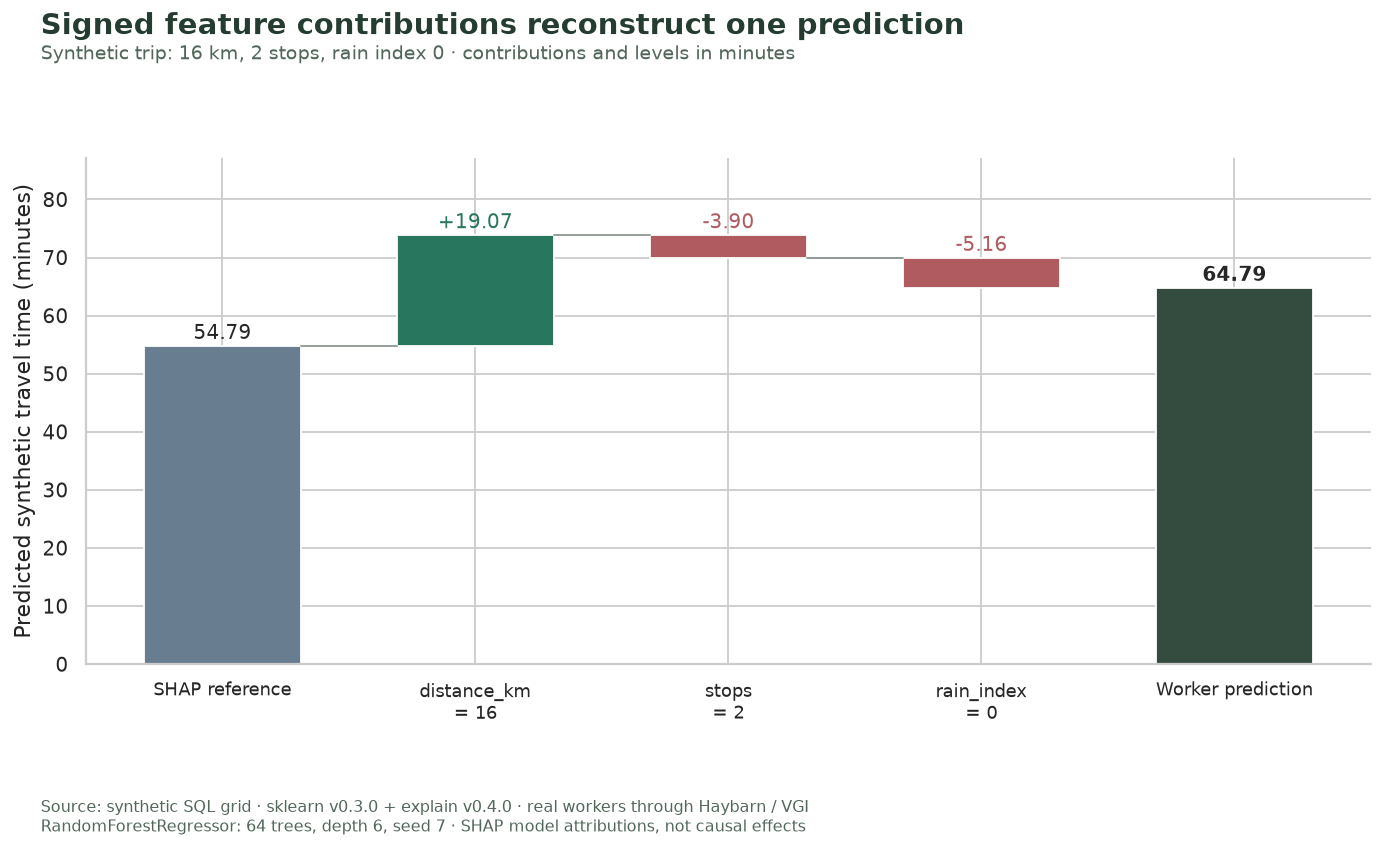

In [17]:
local = local_summary.iloc[0]
fig, ax = plt.subplots(figsize=(11.5, 6.6))
ax.bar(0, local.base_value, color="#697d91", width=0.62)
labels = ["SHAP reference"]
for row in waterfall.itertuples():
    color = "#27765d" if row.shap_value >= 0 else "#b05b60"
    ax.bar(row.position, abs(row.shap_value), bottom=min(row.start_minutes, row.end_minutes), color=color, width=0.62)
    ax.plot(
        [row.position - 0.69, row.position - 0.31], [row.start_minutes, row.start_minutes], color="#8d9690", linewidth=1
    )
    ax.text(
        row.position,
        max(row.start_minutes, row.end_minutes) + 1.2,
        f"{row.shap_value:+.2f}",
        ha="center",
        fontsize=11,
        color=color,
    )
    labels.append(f"{row.feature}\n= {row.feature_value:g}")
ax.bar(4, local.prediction, color="#344b40", width=0.62)
labels.append("Worker prediction")
ax.text(0, local.base_value + 1.2, f"{local.base_value:.2f}", ha="center", fontsize=11)
ax.text(4, local.prediction + 1.2, f"{local.prediction:.2f}", ha="center", fontsize=11, weight="bold")
ax.set_xticks(range(5), labels, fontsize=10)
ax.set_ylabel("Predicted synthetic travel time (minutes)")
ax.set_ylim(0, max(waterfall.end_minutes.max(), local.base_value, local.prediction) * 1.18)
fig.subplots_adjust(left=0.10, right=0.96, bottom=0.22, top=0.81)
finish(
    fig,
    "Signed feature contributions reconstruct one prediction",
    f"Synthetic trip: 16 km, 2 stops, rain index {RAIN_INDEX:g} · contributions and levels in minutes",
    f"waterfall-rain-{RAIN_INDEX:g}.png",
)

In [18]:
largest = waterfall.loc[waterfall.shap_value.abs().idxmax()]
prose(
    f"The worker predicts **{local.prediction:.2f} minutes** for this synthetic trip. "
    f"The SHAP reference is **{local.base_value:.2f} minutes**, and signed contributions sum to "
    f"**{local.signed_contributions:+.2f} minutes**. Their reconstruction differs from the prediction by "
    f"**{local.absolute_error_minutes:.2e} minutes**. The largest local absolute contribution is "
    f"**{largest.feature} ({largest.shap_value:+.2f} minutes)**. "
    "This explains the fitted model’s output; it does not establish that the invented formula "
    "or a real trip is correct."
)

The worker predicts **64.79 minutes** for this synthetic trip. The SHAP reference is **54.79 minutes**, and signed contributions sum to **+10.00 minutes**. Their reconstruction differs from the prediction by **4.97e-14 minutes**. The largest local absolute contribution is **distance_km (+19.07 minutes)**. This explains the fitted model’s output; it does not establish that the invented formula or a real trip is correct.

## Compare local magnitude with cohort importance

Global importance here means **mean absolute SHAP across the fixed 32-row cohort**. Taking absolute values prevents positive and negative contributions from canceling. The local bars use absolute contributions for the one trip; their signs remain in the waterfall. Both measures use minutes, but they answer different questions. The SQL comparison confirms the worker’s importance calculation, rather than assuming its rank describes every row.

In [19]:
%%sql comparison <<
SELECT i.feature, i.rank, i.importance AS cohort_mean_absolute_minutes,
       abs(c.shap_value) AS local_absolute_minutes, c.shap_value AS local_signed_minutes
FROM importance_check i JOIN contributions c USING(feature) JOIN trip t ON t.id = c.id
ORDER BY i.rank;

,feature,rank,cohort_mean_absolute_minutes,local_absolute_minutes,local_signed_minutes
0,distance_km,1,12.646076,19.066378,19.066378
1,rain_index,2,4.118194,5.160283,-5.160283
2,stops,3,3.639431,3.903905,-3.903905


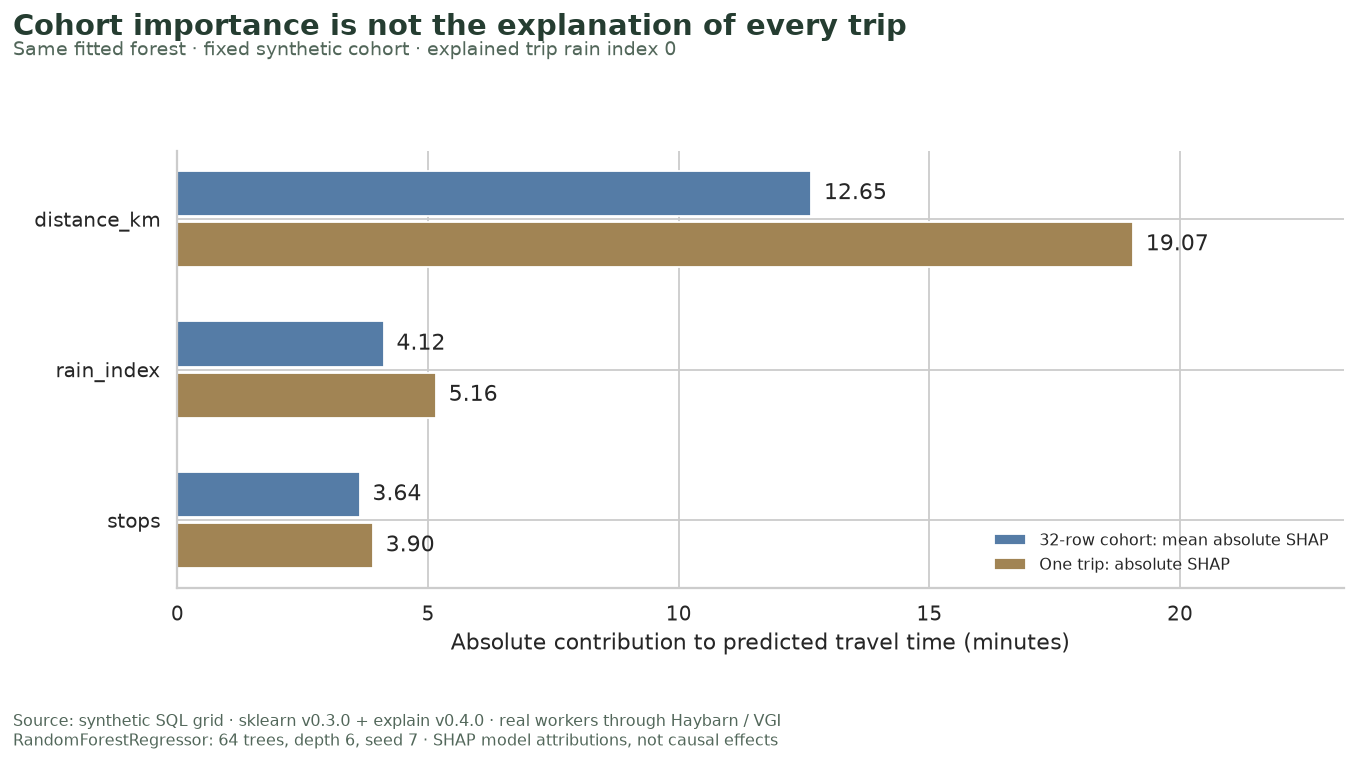

In [20]:
display(comparison)
fig, ax = plt.subplots(figsize=(11.5, 5.9))
y = np.arange(len(comparison))
ax.barh(
    y - 0.17,
    comparison.cohort_mean_absolute_minutes,
    height=0.30,
    color="#557ca6",
    label="32-row cohort: mean absolute SHAP",
)
ax.barh(y + 0.17, comparison.local_absolute_minutes, height=0.30, color="#a18454", label="One trip: absolute SHAP")
for i, row in enumerate(comparison.itertuples()):
    ax.text(row.cohort_mean_absolute_minutes + 0.25, i - 0.17, f"{row.cohort_mean_absolute_minutes:.2f}", va="center")
    ax.text(row.local_absolute_minutes + 0.25, i + 0.17, f"{row.local_absolute_minutes:.2f}", va="center")
ax.set_yticks(y, comparison.feature)
ax.invert_yaxis()
ax.set_xlim(0, max(comparison.cohort_mean_absolute_minutes.max(), comparison.local_absolute_minutes.max()) * 1.22)
ax.set_xlabel("Absolute contribution to predicted travel time (minutes)")
ax.legend(loc="lower right", frameon=False, fontsize=9)
fig.subplots_adjust(left=0.18, right=0.96, bottom=0.23, top=0.80)
finish(
    fig,
    "Cohort importance is not the explanation of every trip",
    f"Same fitted forest · fixed synthetic cohort · explained trip rain index {RAIN_INDEX:g}",
    f"importance-rain-{RAIN_INDEX:g}.png",
)

In [21]:
top = comparison.iloc[0]
prose(
    f"Across the fixed cohort, **{top.feature}** ranks first at "
    f"**{top.cohort_mean_absolute_minutes:.2f} minutes** mean absolute SHAP. "
    f"For this one trip its absolute contribution is **{top.local_absolute_minutes:.2f} minutes**. "
    f"All **{len(checks)} consistency checks** pass. Neither importance measure identifies a causal effect "
    "or establishes performance on future data."
)

Across the fixed cohort, **distance_km** ranks first at **12.65 minutes** mean absolute SHAP. For this one trip its absolute contribution is **19.07 minutes**. All **8 consistency checks** pass. Neither importance measure identifies a causal effect or establishes performance on future data.

## Experiment: change only the trip’s rain state

Set **`RAIN_INDEX = 1.0`**, restart and run all, and compare the prediction and signed waterfall with the default **0.0**. The invented training formula raises minutes in rain; see whether the fitted forest responds in that direction for this trip. A random forest is not constrained to be monotone, so treat the observed change as a model result, not a guaranteed rule.

The training grid, seed, fitted settings and comparison cohort remain fixed. The reference and cohort importance should stay the same; local contributions can change for **several features**, because tree interactions can redistribute credit. Recheck additivity. This model what-if is not a causal intervention. Restore **0.0** for the default, and use the README command to save the experiment separately.

In [22]:
connection.close()

<a href="https://query.farm/"><img src="assets/query-farm-strata-sun.svg" width="310" alt="Query.Farm Strata Sun and wordmark"></a>

[Query.Farm](https://query.farm/) · [VGI](https://query.farm/vgi/) · Synthetic SQL inputs; real scikit-learn and SHAP workers